# **Sesson on Generators**

[Watch Here](https://youtu.be/ZfJoU67tG1A?si=bkM2iovZuNmIZpfi)

# **What is a Generator**

Python generators are a simple way of creating iterators.

## **Range Function using Iterator**

In [ ]:
# iterable

class mera_range:

  def __init__(self,start,end):
    self.start = start
    self.end = end

  def __iter__(self):
    return mera_iterator(self)

# iterator

class mera_iterator:

  def __init__(self,iterable_obj):
    self.iterable = iterable_obj

  def __iter__(self):
    return self

  def __next__(self):

    if self.iterable.start >= self.iterable.end:
      raise StopIteration

    current = self.iterable.start
    self.iterable.start+=1
    return current

## **The Why**

In [ ]:
L = [x for x in range(100000)]

#for i in L:
  #print(i**2)

import sys
sys.getsizeof(L)

800984

In [ ]:
x = range(10000000)

#for i in x:
  #print(i**2)

import sys
sys.getsizeof(x)

48

## **Example 1**

In [ ]:
def gen_demo():

  yield "first statement"
  yield "second statement"
  yield "third statement"

In [ ]:
gen = gen_demo()

for i in gen:
  print(i)

first statement
second statement
third statement


## **Example 2**

In [ ]:
def square(num):
  for i in range(1,num+1):
    yield i**2

In [ ]:
gen = square(10)

print(next(gen))
print(next(gen))
print(next(gen))

for i in gen:
  print(i)

1
4
9
16
25
36
49
64
81
100


## **Python Tutor Demo (yield vs return)**

`yield` pauses the function and remembers its state; `return` ends the function forever.

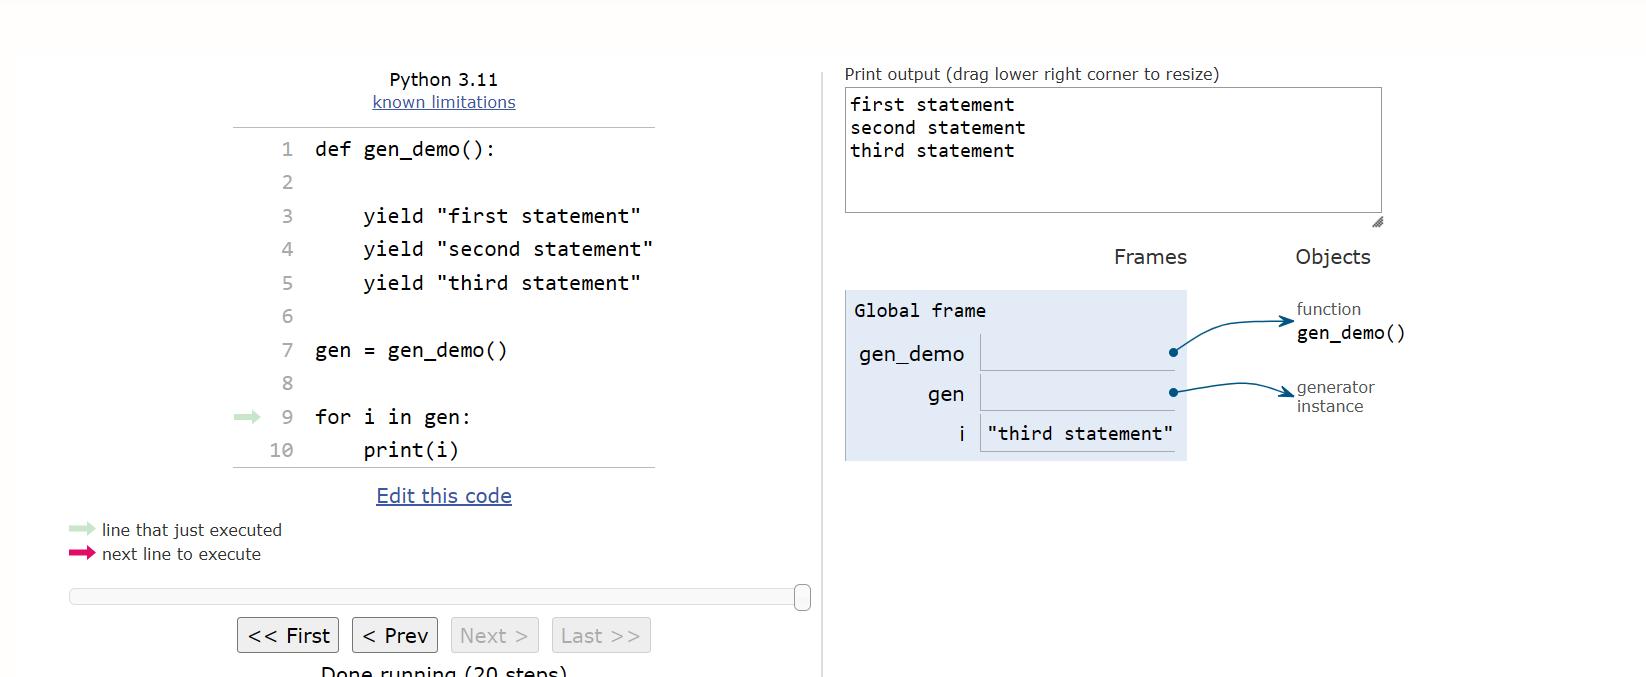



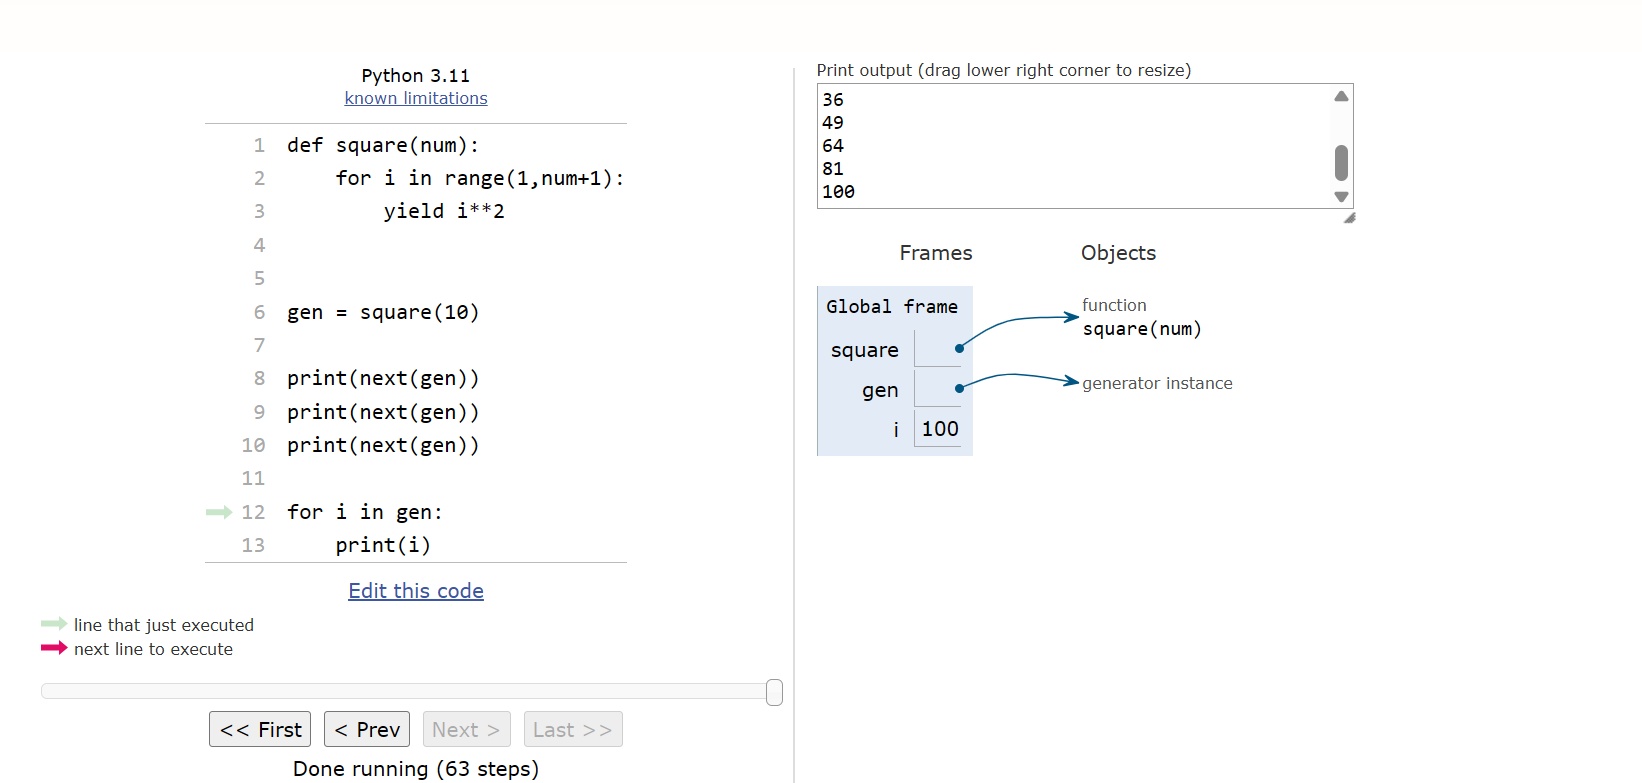

## **Range Function using Generator**

In [ ]:
def mera_range(start,end):

  for i in range(start,end):
    yield i

In [ ]:
for i in mera_range(15,26):
  print(i)

15
16
17
18
19
20
21
22
23
24
25


## **Generator Expression**

In [ ]:
# List Comprehension

L = [i**2 for i in range(1,101)]

In [ ]:
# Generator Expression

gen = (i**2 for i in range(1,101))

for i in gen:
  print(i)

1
4
9
16
25
36
49
64
81
100
121
144
169
196
225
256
289
324
361
400
441
484
529
576
625
676
729
784
841
900
961
1024
1089
1156
1225
1296
1369
1444
1521
1600
1681
1764
1849
1936
2025
2116
2209
2304
2401
2500
2601
2704
2809
2916
3025
3136
3249
3364
3481
3600
3721
3844
3969
4096
4225
4356
4489
4624
4761
4900
5041
5184
5329
5476
5625
5776
5929
6084
6241
6400
6561
6724
6889
7056
7225
7396
7569
7744
7921
8100
8281
8464
8649
8836
9025
9216
9409
9604
9801
10000


## **Practical Example**

In [ ]:
import os
import cv2

def image_data_reader(folder_path):

  for file in os.listdir(folder_path):
    f_array = cv2.imread(os.path.join(folder_path,file))
    yield f_array


In [ ]:
gen = image_data_reader('C:/Users/91842/emotion-detector/train/Sad')

next(gen)
next(gen)

next(gen)
next(gen)

array([[[ 38,  38,  38],
        [ 26,  26,  26],
        [ 23,  23,  23],
        ...,
        [198, 198, 198],
        [196, 196, 196],
        [167, 167, 167]],

       [[ 32,  32,  32],
        [ 25,  25,  25],
        [ 26,  26,  26],
        ...,
        [194, 194, 194],
        [204, 204, 204],
        [181, 181, 181]],

       [[ 44,  44,  44],
        [ 42,  42,  42],
        [ 38,  38,  38],
        ...,
        [156, 156, 156],
        [214, 214, 214],
        [199, 199, 199]],

       ...,

       [[150, 150, 150],
        [165, 165, 165],
        [186, 186, 186],
        ...,
        [229, 229, 229],
        [226, 226, 226],
        [239, 239, 239]],

       [[145, 145, 145],
        [156, 156, 156],
        [180, 180, 180],
        ...,
        [227, 227, 227],
        [228, 228, 228],
        [221, 221, 221]],

       [[144, 144, 144],
        [150, 150, 150],
        [172, 172, 172],
        ...,
        [211, 211, 211],
        [189, 189, 189],
        [217, 217, 217]]

## **Benefits of using a Generator**

### **1. Ease of Implementation**

In [ ]:
# Range function using class

class mera_range:

  def __init__(self,start,end):
    self.start = start
    self.end = end

  def __iter__(self):
    return mera_iterator(self)

In [ ]:
# iterator

class mera_iterator:

  def __init__(self,iterable_obj):
    self.iterable = iterable_obj

  def __iter__(self):
    return self

  def __next__(self):

    if self.iterable.start >= self.iterable.end:
      raise StopIteration

    current = self.iterable.start
    self.iterable.start+=1
    return current

In [ ]:
# Range function using Generator

def mera_range(start,end):

  for i in range(start,end):
    yield i

### **2. Memory Efficient**

In [ ]:
L = [x for x in range(100000)]
gen = (x for x in range(100000))

import sys

print('Size of L in memory',sys.getsizeof(L))
print('Size of gen in memory',sys.getsizeof(gen))

Size of L in memory 800984
Size of gen in memory 192


### **3. Representing Infinite Streams**

In [ ]:
def all_even():
  n = 0
  while True:
    yield n
    n += 2

In [ ]:
even_num_gen = all_even()
next(even_num_gen)
next(even_num_gen)

2

### **4. Chaining Generators**

In [ ]:
def fibonacci_numbers(nums):
  x, y = 0, 1
  for _ in range(nums):
    x, y = y, x+y
    yield x

def square(nums):
  for num in nums:
    yield num**2

print(sum(square(fibonacci_numbers(10))))

4895
